# 2. The climb: from a naive CNN to the leader's accuracy at a fraction of its cost

Thirteen experiments, each with **one question**, a **prediction** written before the runs,
3 seeds per setting, and a **decision**. All are chosen on split 11, where BuzinD's own
submission scores **96.67%** (the orange line). The settings are in `experiments.py`;
every run is a line in `runs/`, trained on a rented GPU by `search.py` (`pod/README.md`).

How to read the charts: a dot is the mean of 3 seeds; its line is ±1 standard error.
Two settings whose dots are less than about two standard errors apart may differ by luck.
"Check" accuracy is measured on the 4,320 held-back images; "training" accuracy on the
(augmented) images the network learns from, during the last epoch.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["png"]
import matplotlib.pyplot as plt
from analyze import plot_curves, plot_frontier, plot_settings, show

BAR = 96.67  # BuzinD's submission, scored on split 11
plt.rcParams["figure.dpi"] = 80

## Experiment 0: where does the naive CNN stand?

`c16 p c32 p c64 p fl`: three 3x3 convolutions with ReLU and max pooling, flatten, one
linear layer; Adam at its default rate 1e-3, batch 64, 10 epochs.

**Prediction:** about 80%. Small CNNs do well on EuroSAT.

experiment    setting                            n    check acc  1 view  train  TFLOP  MFLOP   params  gpu s
0-naive       naive 10 ep                        3  78.65 ±1.93   78.65  83.60  11.05   22.5    64554     49
0-naive       naive 30 ep                        3  84.34 ±0.18   84.34  93.99  33.15   22.5    64554    118


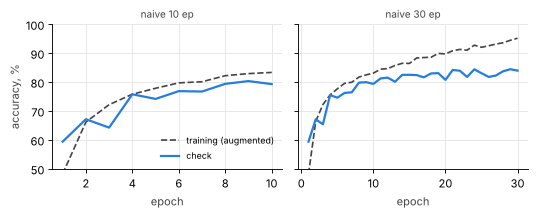

In [2]:
show("0-naive")
plot_curves("0-naive", ["naive 10 ep", "naive 30 ep"]);

**Result:** 78.7% at 10 epochs, with a large spread between seeds (±1.9). At 30
epochs, 84.3%, but look at the curves: training accuracy keeps climbing to 94% while
check accuracy flattens at about 83% after epoch 15. The network has started to
**memorize** the training images.

**Decision:** two problems to fix: it learns slowly (79% after 10 epochs) and, given
time, memorizes.

## Experiment 1: is Adam's default rate right?

**Prediction:** a somewhat higher rate learns faster in 10 epochs.

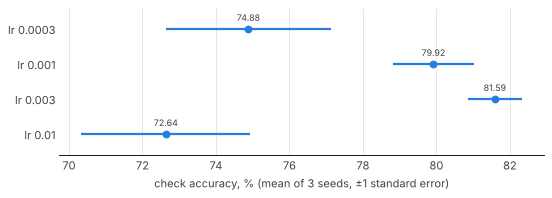

In [3]:
plot_settings("1-lr");

**Result:** 3e-3 is best (81.6), 1e-2 too high (72.6), 3e-4 too slow (74.9).
**Decision:** a small gain; the rate is not the main problem. Keep it in mind.

## Experiment 2: normalize the input, or every layer?

The pixels arrive as numbers from 0 to 1, all positive, with a mean far from zero.
A layer whose inputs are all positive gets gradients that push all its weights in the
same direction, which slows learning. Two generic fixes: **standardize** the input
(subtract the mean colour, divide by its spread) or **batch normalization** after every
convolution (standardize every layer's output, batch by batch).

**Prediction:** both help; batch norm more.

experiment    setting                            n    check acc  1 view  train  TFLOP  MFLOP   params  gpu s
2-inputs      standardize                        3  87.35 ±0.35   87.35  92.83  11.05   22.5    64554     37
2-inputs      batch norm                         3  82.91 ±1.67   82.91  93.46  11.05   22.5    64666     43
2-inputs      batch norm lr 3e-3                 3  69.43 ±7.01   69.43  92.43  11.05   22.5    64666     43
2-inputs      batch norm lr 1e-2                 3  79.80 ±1.67   79.80  90.24  11.05   22.5    64666     43


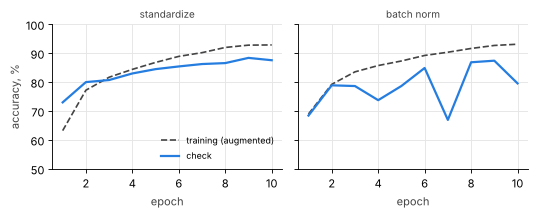

In [4]:
show("2-inputs")
plot_curves("2-inputs", ["standardize", "batch norm"]);

**Result:** standardizing the input is worth **+8.7 points** (87.4%) at no cost.
Batch norm learns as fast on the training images (93%), but its check accuracy swings
wildly from epoch to epoch (57% to 87%): where training stops is a lottery. The reason:
with a constant, high learning rate the weights keep moving a lot every step, and batch
norm's running averages (used when answering) lag behind them.

**Decision:** keep batch norm, but fix the end point (experiment 4).

## Experiment 3: flatten, or average-pool into the classifier?

Flattening the last 8x8x64 feature map gives the linear layer 41,000 weights; averaging
each channel over the image (global average pooling) gives it 640.

**Prediction:** pooling loses nothing and saves parameters.

In [5]:
show("3-head")

experiment    setting                            n    check acc  1 view  train  TFLOP  MFLOP   params  gpu s
3-head        flatten                            3  86.68 ±2.15   86.68  93.38  11.05   22.5    64666     44
3-head        gap                                3  75.90 ±5.39   75.90  87.74  11.01   22.4    24346     46
3-head        gap, 2x wider                      3  79.39 ±3.88   79.39  90.40  41.59   82.6    94762     49
3-head        gap, conv at 8x8                   3  87.97 ±1.68   87.97  91.76  15.90   31.9    98970     53


**Result:** unreadable: every setting uses batch norm, so every result is a draw
from the lottery of experiment 2 (standard errors of 2 to 5 points).

**Decision:** an experiment whose noise is bigger than its effect answers nothing.
Ask again after experiment 4.

## Experiment 4: does a learning-rate schedule settle batch norm?

**Warm-up then cosine annealing:** the rate rises linearly over the first 10% of the
steps (big steps on random weights can blow up), then falls along a half cosine to zero.
At the end the steps are tiny, so the weights and batch norm's averages agree.

**Prediction:** the swings disappear, and the end point is the top of the curve.

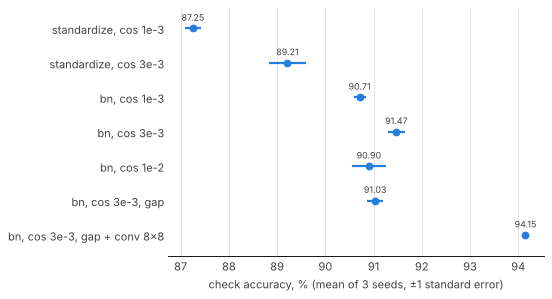

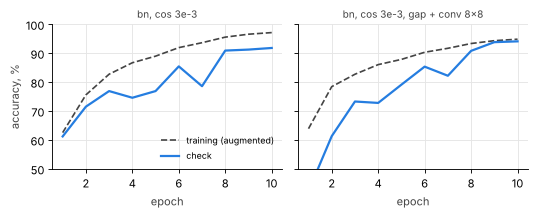

In [6]:
plot_settings("4-schedule")
plot_curves("4-schedule", ["bn, cos 3e-3", "bn, cos 3e-3, gap + conv 8x8"]);

**Result:** batch norm + cosine at 3e-3: **91.5 ± 0.2**, from 83-87 with swings:
the noise is gone (standard error 0.2 instead of 2). Standardizing with cosine: 89.2.
Now the head question can be read: flatten 91.5 (but training 97: memorizing), average
pooling 91.0, and **one more convolution at 8x8, then average pooling: 94.2**, with
training accuracy equal to check accuracy.

**Decision:** batch norm, warm-up + cosine, Adam 3e-3; head: a convolution at 8x8, then
global average pooling.

## Experiment 5: augmentation, to stop the memorizing

A photo taken from above has no "up": a forest mirrored or turned by 90 degrees is still a
forest. The 8 symmetries of a square (4 turns, each mirrored or not, the group *D4*) give
8 equally valid copies of every image, and small shifts give more. Every batch gets
random ones, so the network never sees the same image twice.

**Prediction:** +2 points at 30 epochs.

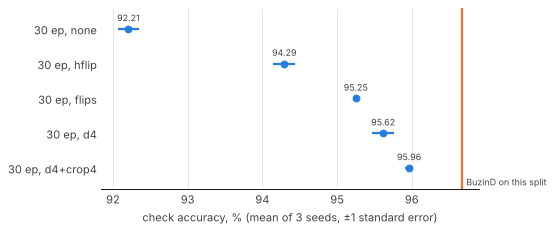

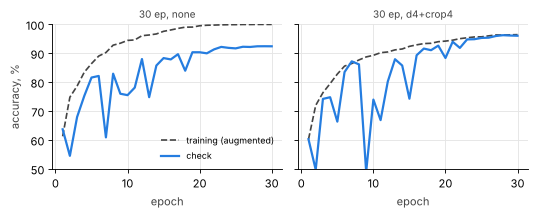

In [7]:
plot_settings("5-augment", bar=BAR)
plot_curves("5-augment", ["30 ep, none", "30 ep, d4+crop4"]);

**Result:** without augmentation the network memorizes completely (training 99.9%,
check 92.2%). Each symmetry adds: mirror 94.3, all flips 95.3, all 8 symmetries 95.6, and
shifts of up to 4 pixels **96.0 ± 0.05**, with training accuracy (96.5) now close to
check accuracy.

**Decision:** all 8 symmetries plus shifts. But this network costs 22.5 MFLOP per image:
30 epochs on all 21,600 images would be 41 TFLOP, far above BuzinD's 26. From here on,
every gain has to be paid for in FLOPs.

## Experiment 6: which layers earn their FLOPs?

With the 8x8 convolution the network is `c16 p c32 p c64 p c128 gap`, 32 MFLOP. By the
arithmetic of notebook 1, the last three convolutions cost 9.4 MFLOP each (half the
image, twice the channels), the first 3.5.

**Prediction:** the full-size 64x64 layer earns the least: there is little to see in a
3x3 patch of a 64x64 photo that a stride-2 layer would miss.

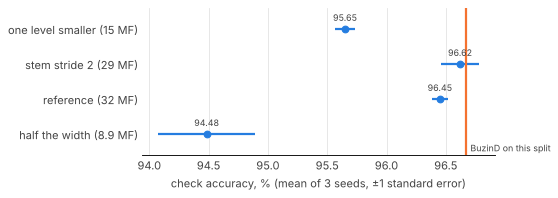

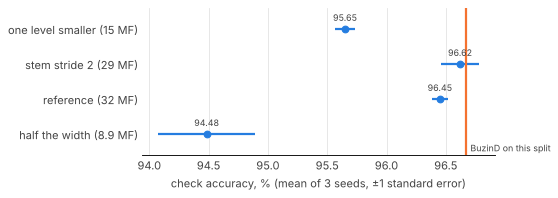

In [8]:
plot_settings("6-where", bar=BAR)

**Result:** a first convolution with stride 2 (29 MF): 96.62, a tie with the
reference (32 MF, 96.45). Starting at 16x16 instead of 32x32 (15 MF): −1.0. Half the
width (8.9 MF): −2.0. In every setting **training accuracy equals check accuracy**: these
networks no longer memorize; they **underfit**.

**Decision:** the 64x64 layer is wasted (stride 2 in the first layer); the 32x32 stage
earns its FLOPs. An underfitting network needs more capacity or better-spent compute.

## Experiment 7: at ~10 MFLOP, which kind of block buys the most?

Four generic blocks, each sized to about 10 MFLOP per image:
**plain** (conv, BN, ReLU), **residual** (two convolutions added to a shortcut, so the
block only has to learn a correction), **depthwise-separable** (a 3x3 convolution per
channel, then a 1x1 convolution that mixes them: about 8x cheaper per layer), and
**inverted residual** (expand with 1x1, depthwise 3x3, project back, with a shortcut).

**Prediction:** separable wins: it buys the most layers for the FLOPs.

experiment    setting                            n    check acc  1 view  train  TFLOP  MFLOP   params  gpu s
7-blocks      plain (8.9 MF)                     3  94.47 ±0.27   94.47  94.03  12.84    8.8    25298    183
7-blocks      plain, smaller images (8.6 MF)     3  94.29 ±0.20   94.29  93.94  13.07    8.6    56086    182
7-blocks      residual (11.5 MF)                 3  95.18 ±0.02   95.18  95.04  17.58   11.5    76818    292
7-blocks      separable (11.9 MF)                3  96.17 ±0.13   96.17  96.48  53.90   11.9    38602    404
7-blocks      inverted residual (10.0 MF)        3  96.11 ±0.09   96.11  95.76  48.70   10.0    34874    455


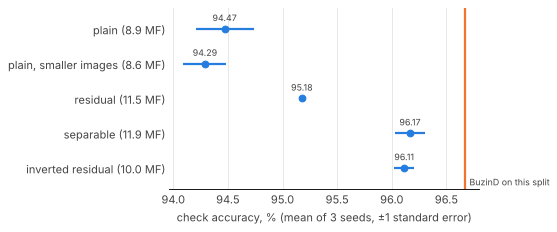

In [9]:
show("7-blocks")
plot_settings("7-blocks", bar=BAR);

**Result:** separable 96.2 and inverted residual 96.1 lead; residual 95.2 beats
plain 94.5. But look at the TFLOP column: the separable network costs 11.9 MFLOP per image,
yet its training is **counted as 54 TFLOP**, against 18 for the residual one. That is
the counter's quirk from notebook 1: the backward pass of a depthwise convolution is
counted as if it were dense. On this leaderboard, those blocks cost 3-4 times what they
should, and they are also twice as slow per FLOP on a CPU.

**Decision:** residual blocks, the best of the blocks the counter charges fairly.

## Experiment 8: underfitting, so what makes each FLOP of training go further?

Asked of a cheap **probe**, `c8s2 r16s2 r32s2 r64 gap` (11.5 MF, 95.18 in exp. 7), so a
whole sweep costs little. Batch size does not change an epoch's FLOPs, only how many
updates they buy. SGD with Nesterov momentum and weight decay is the classic alternative
to Adam for CNNs.

**Prediction:** a better learning rate is worth about half a point.

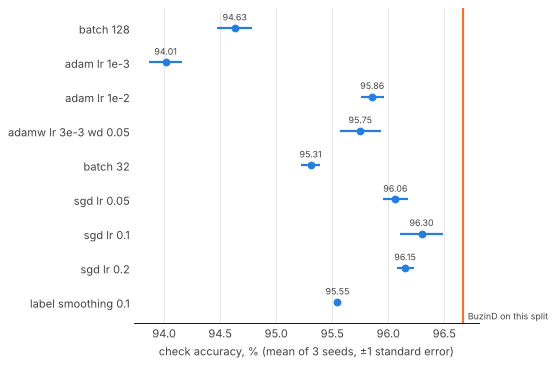

In [10]:
plot_settings("8-recipe", bar=BAR);

**Result:** **SGD (Nesterov momentum 0.9, weight decay 5e-4) at lr 0.1: 96.30 ±
0.19**, +1.1 over Adam 3e-3 (real); 0.05 and 0.2 are close. Adam at 1e-2 (95.86) and AdamW
(95.75) close part of the gap. Batch 32: within luck, and twice as slow on a CPU; batch
128: −0.55 (real), fewer updates for the same FLOPs. Label smoothing, a regularizer,
does not help a network that underfits.

**Free accuracy:** every run also answered the check images with 1, 2, 4 and 8 turned
copies averaged (test-time augmentation). It costs nothing to train, only per image:

In [11]:
from analyze import mean_se
from search import load

for label in ("sgd lr 0.1", "adam lr 1e-2"):
    rows = [r for r in load("8-recipe") if r["label"] == label]
    print(
        f"{label:14}",
        "  ".join(
            f"{v} views {mean_se([100 * r['acc_views'][str(v)] for r in rows])[0]:.2f}"
            for v in (1, 2, 4, 8)
        ),
    )

sgd lr 0.1     1 views 96.30  2 views 96.60  4 views 96.89  8 views 97.04
adam lr 1e-2   1 views 95.86  2 views 96.15  4 views 96.42  8 views 96.50


Each doubling of the views adds 0.15-0.3 points, and costs one more forward pass
per image. BuzinD answers with 8 views (119 MFLOP).

**Decision:** SGD 0.1, batch 64; answer with several views (how many: exp. 13).

## Experiment 9: residual networks that keep a 32x32 stage

Experiment 6 said the 32x32 stage earns its FLOPs; the probe goes from 32x32 straight to
16x16. Do residual networks with a real 32x32 stage do better (Adam, 30 epochs)?

**Prediction:** yes, by about half a point.

In [12]:
show("9-residual")

experiment    setting                            n    check acc  1 view  train  TFLOP  MFLOP   params  gpu s
9-residual    r at 32, 16, 8 (22.5 MF)           3  96.20 ±0.27   96.20  96.36  34.71   22.5    76818    309
9-residual    plain, same stages (29 MF)         3  96.65 ±0.24   96.65  96.66  44.95   29.2    98970    190
9-residual    c at 32, r at 16, 8 (20.3 MF)      3  95.86 ±0.07   95.86  96.21  31.09   20.3    75706    262


**Result:** plain at 32, 16, 8 (29 MF) 96.65; residual at 32, 16, 8 (22.5 MF)
96.20; but they cost 2-3 times the probe.

**Decision:** a better score for more FLOPs is not an answer. Compare at equal compute.

## Experiment 10: a fixed budget, where should the compute go?

Every setting gets the same training budget, about **345 MFLOP-epochs** (the probe's
11.5 MF x 30 epochs; BuzinD spends about 420): a network twice as costly trains half as
many epochs.

**Prediction:** width and epochs about equally good; depth a little better.

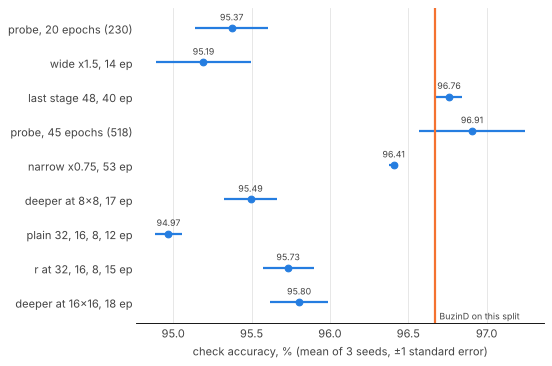

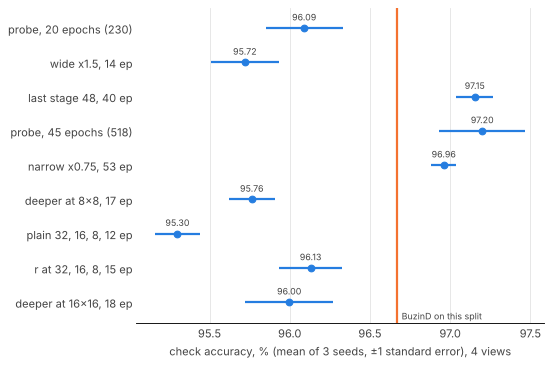

In [13]:
plot_settings("10-budget", bar=BAR)
plot_settings("10-budget", bar=BAR, views=4);

**Result:** clear, and not what I predicted. At equal compute, **a smaller network
trained longer wins**: the probe with its last stage cut from 64 to 48 channels (8.7 MF)
for 40 epochs scores **96.76 ± 0.08** (97.15 with 4 views), the probe for 30 epochs 96.30,
and every wider or deeper network, trained for 12-18 epochs, 95.0-95.8. Training longer
pays: the probe at 20 / 30 / 45 epochs scores 95.37 / 96.30 / 96.91. Too small is no good
either: 0.75x the width for 53 epochs, 96.41.

**Decision:** candidate `c8s2 r16s2 r32s2 r48 gap` for 40 epochs. It already beats
BuzinD's 96.67 on this split, with less compute. Is it a local best?

## Experiment 11: how does the candidate trade compute for accuracy?

**Prediction:** about +0.5 points for every 1.5 times more epochs, as for the probe.

In [14]:
show("11-epochs", "10-budget")

experiment    setting                            n    check acc  1 view  train  TFLOP  MFLOP   params  gpu s
11-epochs     30 epochs                          3  96.30 ±0.11   96.30  95.81  13.35    8.7    55314    286
11-epochs     50 epochs                          3  96.98 ±0.07   96.98  96.67  22.26    8.7    55314    467
11-epochs     60 epochs                          3  97.08 ±0.10   97.08  96.97  26.71    8.7    55314    561
10-budget     probe, 20 epochs (230)             3  95.37 ±0.23   95.37  94.78  11.72   11.5    76818    194
10-budget     wide x1.5, 14 ep                   3  95.19 ±0.30   95.19  94.53  18.30   25.4   171670    129
10-budget     last stage 48, 40 ep               3  96.76 ±0.08   96.76  96.41  17.80    8.7    55314    366
10-budget     probe, 45 epochs (518)             3  96.91 ±0.34   96.91  96.59  26.38   11.5    76818    419
10-budget     narrow x0.75, 53 ep                3  96.41 ±0.03   96.41  96.09  17.63    6.5    43504    493
10-budget     deepe

**Result:** 30 / 40 / 50 / 60 epochs: 96.30 / 96.76 / 96.98 / 97.08 (4 views:
96.90 / 97.15 / 97.25 / 97.46): diminishing returns. On all 21,600 images, 50 epochs
would cost 27.8 TFLOP, more than BuzinD's whole budget, for +0.1 to +0.3.

**Decision:** stay at 40 epochs.

## Experiment 12: is the candidate's shape a local best?

Its neighbours, one width changed at a time, all at 40 epochs.

**Prediction:** yes; narrower loses a little, wider gains a little for its FLOPs.

experiment    setting                            n    check acc  1 view  train  TFLOP  MFLOP   params  gpu s
12-neighbours last stage 40 (7.6 MF)             3  96.60 ±0.10   96.60  96.25  15.44    7.6    46290    365
12-neighbours last stage 32 (6.5 MF)             3  96.74 ±0.22   96.74  96.25  13.12    6.5    37330    337
12-neighbours last stage 56 (10.0 MF)            3  96.71 ±0.05   96.71  96.49  20.47   10.0    65490    363
12-neighbours middle 24 (7.6 MF)                 3  96.72 ±0.06   96.72  96.24  15.38    7.6    46114    369
12-neighbours first 12, middle 24 (6.8 MF)       3  96.10 ±0.19   96.10  95.51  13.71    6.8    43802    363
12-neighbours stem 12 (9.3 MF)                   3  96.97 ±0.10   96.97  96.61  18.79    9.3    56070    361


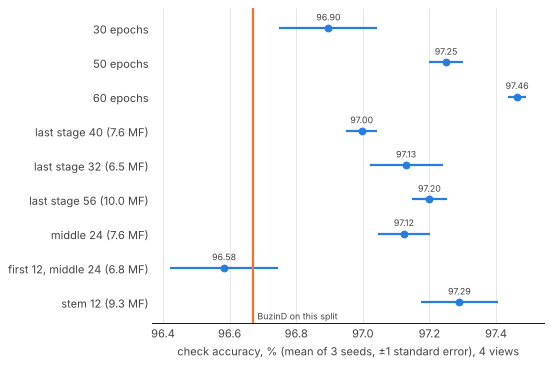

In [15]:
show("12-neighbours")
plot_settings("11-epochs", "12-neighbours", bar=BAR, views=4);

**Result:** a surprise in our favour: cutting the last stage from 48 to 32
channels (6.5 MF, 25% fewer FLOPs) scores the same (96.74 ± 0.22; 97.13 with 4 views,
97.14 with 8). A wider stem (9.3 MF) scores 96.97, +0.2: within luck. Cutting the first
block to 12 channels costs 0.66 (real): the cheap early layers matter.

**Decision, the choice:** `c8s2 r16s2 r32s2 r32 gap`, 40 epochs, answering with
**4 views** (8 add nothing for it). Among settings that tie, take the cheapest.

## Every setting of the climb, against the bar

Accuracy (4 views) against training compute, for every setting since SGD (exp. 8):

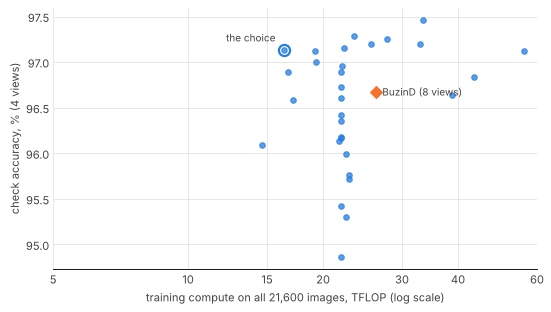

In [16]:
plot_frontier(
    ["8-recipe", "9-residual", "10-budget", "11-epochs", "12-neighbours"],
    bar_acc=BAR,
    bar_tflop=26.2,
    chosen="last stage 32 (6.5 MF)",
);

Everything up and to the left of BuzinD's diamond beats it on both accuracy and
training compute. `3-confirm-and-submit.ipynb` checks the choice on images that played
no part in making it, takes it apart to see what each piece is worth, and submits it.